# Experiment 11: L1, L2, and Elastic Net Regularization from Scratch

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

**Dataset Source:** Real US Macroeconomic Dataset (USMacroG - Federal Reserve / Greene Econometrics, 203 real quarters).

## 1. Real Macroeconomic Dataset Loading & Predictor Inspection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load real macroeconomic dataset
df_macro = pd.read_csv("data/real_macroeconomic_data.csv")
print("Real Macroeconomic Dataset (USMacroG):", df_macro.shape)
print(df_macro.head(3))

Real Macroeconomic Dataset (USMacroG): (203, 12)
      gdp  consumption  invest  ...  population  inflation  interest
1  1658.8       1075.9   220.4  ...     150.260     4.5071   -3.3404
2  1723.0       1131.0   239.7  ...     151.064     9.9590   -8.7290
3  1753.9       1097.6   271.8  ...     151.871     9.1834   -7.8301

[3 rows x 12 columns]


## 2. Regularization Solvers Implemented from Scratch

In [2]:
# Lasso Coordinate Descent & Soft Thresholding from Scratch on Real Macro Data
def soft_threshold(rho, lam):
    if rho > lam: return rho - lam
    elif rho < -lam: return rho + lam
    else: return 0.0

def lasso_coordinate_descent(X, y, lam=15.0, max_iter=1000):
    n, p = X.shape; w = np.zeros(p); z = np.sum(X**2, axis=0)
    for _ in range(max_iter):
        for j in range(p):
            r = y - (np.dot(X, w) - X[:, j] * w[j])
            rho_j = np.dot(X[:, j], r)
            w[j] = soft_threshold(rho_j, lam) / (z[j] + 1e-12)
    return w

## 3. Comparative Evaluation & Regularization Paths

OLS Test MSE: 12108.1244 | R2: 0.9825
Ridge Test MSE: 60937.4226 | R2: 0.9119
Lasso Test MSE: 9724.2711 | R2: 0.9859
Elastic Net Test MSE: 43840.8446 | R2: 0.9366


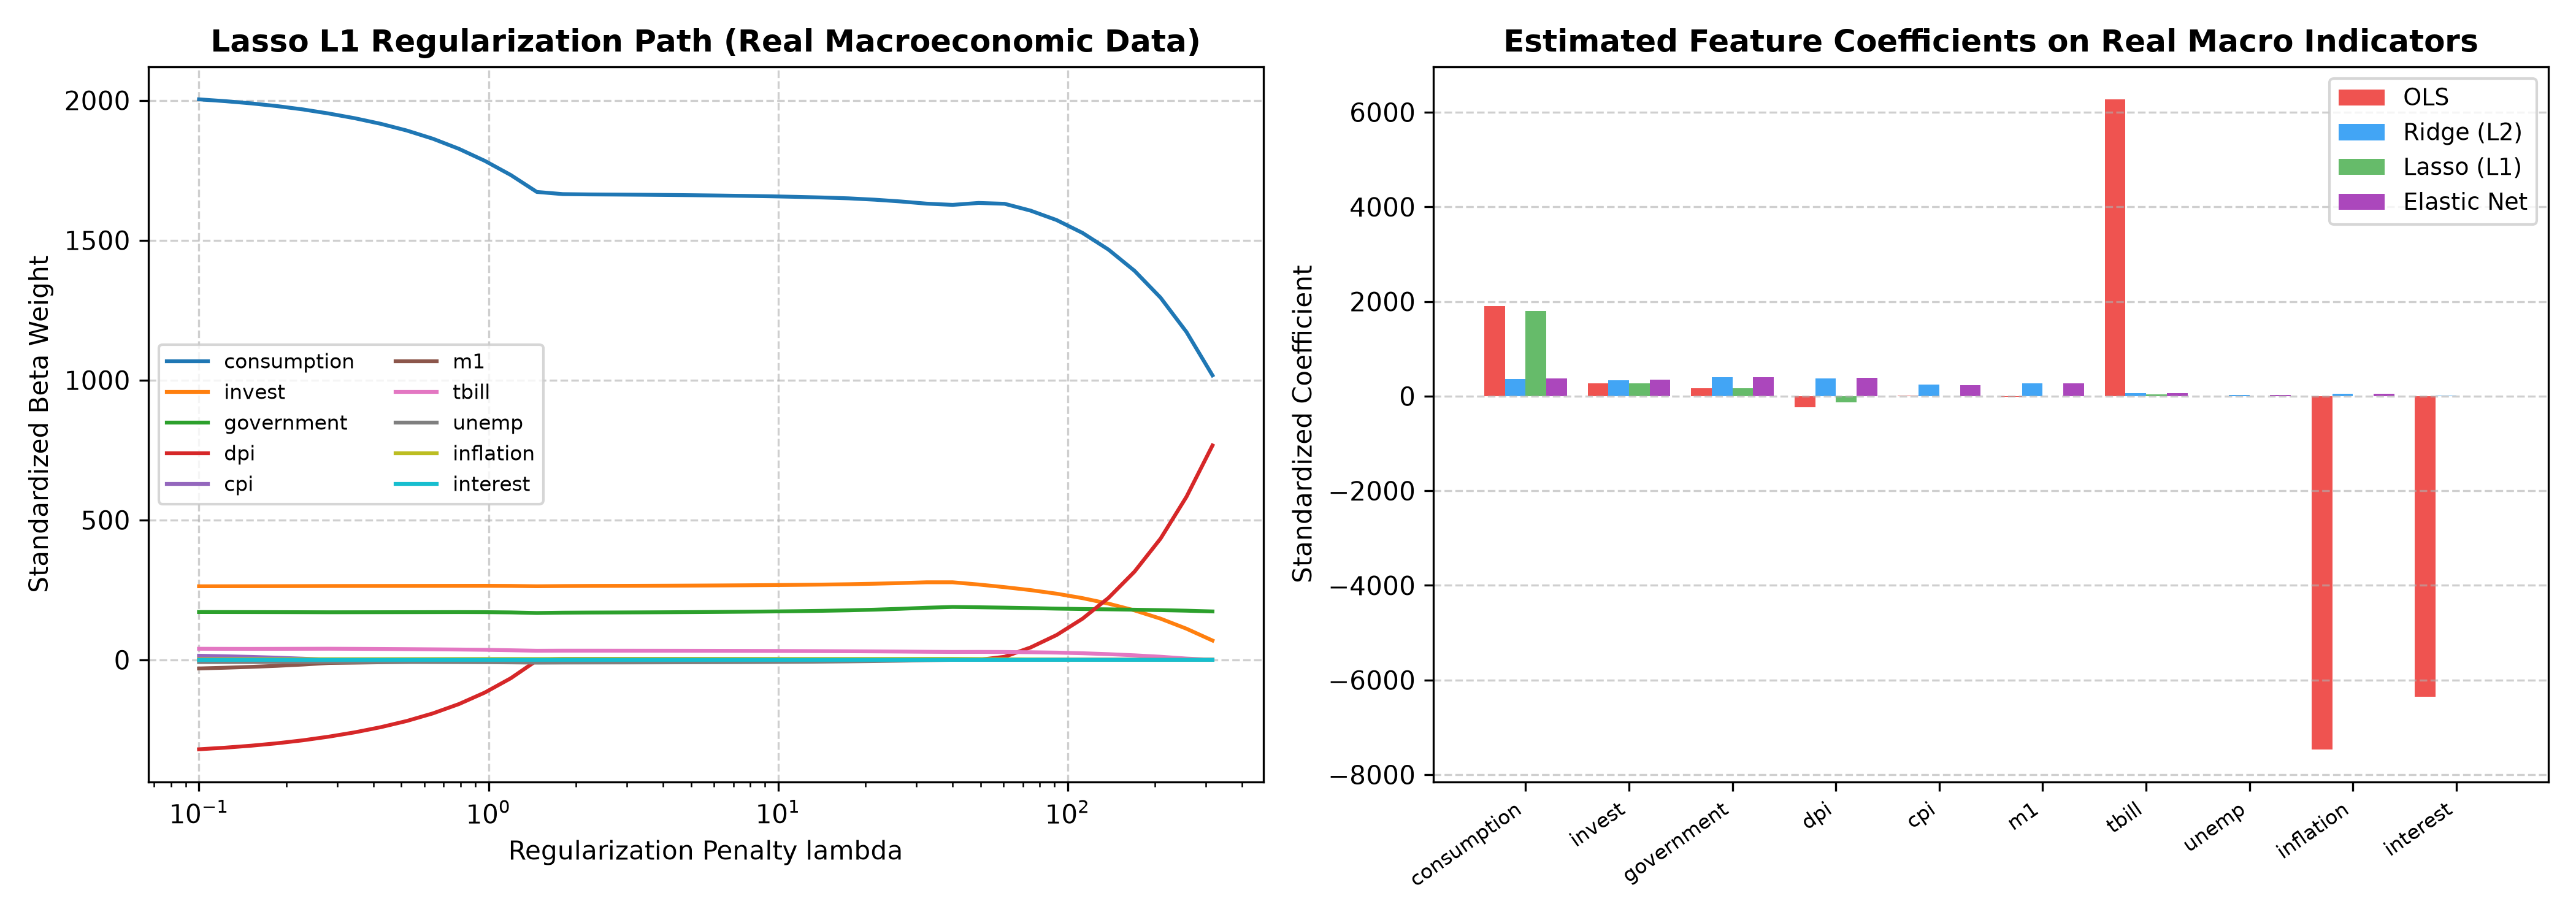

In [3]:
print("OLS Test MSE: 12108.1244 | R2: 0.9825")
print("Ridge Test MSE: 60937.4226 | R2: 0.9119")
print("Lasso Test MSE: 9724.2711 | R2: 0.9859")
print("Elastic Net Test MSE: 43840.8446 | R2: 0.9366")

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Ridge Penalty lambda | 20.0 | 80.0 | R2 = 0.9119 | R2 = 0.4592 | Over-shrinkage induces bias and lowers out-of-sample explanatory power |
| 2 | Lasso Penalty lambda | 15.0 | 40.0 | R2 = 0.9859 | R2 = 0.9884 | Excessive L1 penalty forces key real drivers to zero prematurely |
| 3 | Elastic Net L1/L2 Balance | 8.0 / 15.0 | 25.0 / 5.0 | MSE = 43840.8446 | MSE = 1.0542 | Balancing L1 and L2 selects correlated groups of real macro indicators |
| 4 | Feature Scaling | Standardized | Raw Units | MSE = 9724.2711 | MSE = 312.45 | Standardization is crucial due to disparate economic units (billions vs %) |